# 05 · The demo: searching a hierarchy with a moving frame

Companion notebook for *Questioning the mathematical foundations of AI*, Dr Ana Rojo-Echeburúa, PyCon España 2026.

## What this notebook does

This is the whole talk in one small Python demo. We put a tiny hierarchy (animals and documents) into a curved space, the Poincaré disk. Then we search it with a **moving frame**, which moves every comparison into a standard position before measuring anything. Finally we check two things: that the answer is correct, and that it doesn't depend on any arbitrary choice.

The recipe from the talk has four steps:

1. **Embed.** Put a small hierarchy in the 2-dimensional Poincaré disk.
2. **Frame.** For a query point $a$, find the isometry of the disk that sends $a$ to the centre.
3. **Invariant.** Apply it to $b$ and rotate $b$ onto the real axis. The only thing left is $r = |\rho(b)|$, and the invariant is $2\operatorname{artanh}(r)$.
4. **Search and check.** Rank by the invariant, check it's the hyperbolic distance, and check the ranking doesn't change under any isometry.

**Why bother?** Steck, Ekanadham & Kallus (WWW '24 Companion) showed that cosine similarity between learned embeddings can be arbitrary, because training ignores a symmetry that the metric doesn't (notebook 01, Step 9). A moving frame removes that freedom before you compare. You decide which transformations don't matter, put everything in standard position for them, and measure only what's left. The theory behind it is in notebook 03.

## Setup

The outputs in this notebook come from **gensim 4.4.0** with `seed=0`. If your gensim version is different, the embedding (and so the neighbours) can come out slightly differently, so check the version printed below first.

In [1]:
import logging
import numpy as np
import matplotlib.pyplot as plt
import gensim
from gensim.models.poincare import PoincareModel

logging.getLogger("gensim").setLevel(logging.WARNING)
SEED = 0
np.random.seed(SEED)

BG, TEXT = "#CFD5D3", "#030303"
BROWN, DARK_BROWN, SLATE, LIGHT_GREY = "#7F584A", "#4F3733", "#767F87", "#A9B0B4"
QUERY, POINT = TEXT, BROWN
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": TEXT, "axes.labelcolor": TEXT, "axes.edgecolor": TEXT,
    "font.size": 11, "figure.dpi": 110,
})

def disk(ax, title=None):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=TEXT, lw=1.2))
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal"); ax.axis("off")
    if title: ax.set_title(title, fontsize=11)

print("gensim", gensim.__version__)

gensim 4.4.0


**What you're seeing:** gensim 4.4.0, the same version as the talk, so every number below should match the slides exactly.

## Step 1 · Embed the hierarchy

Ten "is a" relations: three mammals, two birds, both kinds of animal, and a separate branch of three kinds of document. gensim's `PoincareModel` (Nickel & Kiela, NeurIPS 2017) places all twelve words in the 2-dimensional Poincaré disk.

We store each point as a **complex number**, $z = x + iy$. The isometries of the disk (the transformations that keep every hyperbolic distance the same) are fractions of complex numbers, so with complex numbers the maths in Step 2 becomes one line of code.

In [2]:
rels = [("dog", "mammal"), ("cat", "mammal"), ("whale", "mammal"),
        ("mammal", "animal"), ("eagle", "bird"), ("owl", "bird"), ("bird", "animal"),
        ("invoice", "document"), ("receipt", "document"), ("contract", "document")]
model = PoincareModel(rels, size=2, negative=2, seed=0)
model.train(epochs=300)
emb = {w: complex(*model.kv[w]) for w in model.kv.index_to_key}

print(f"{'word':<10}{'|z|':>7}")
for w in sorted(emb, key=lambda w: abs(emb[w])):
    print(f"{w:<10}{abs(emb[w]):7.3f}")

word          |z|
animal      0.122
mammal      0.300
cat         0.366
bird        0.427
contract    0.476
document    0.484
owl         0.513
receipt     0.583
whale       0.610
dog         0.760
eagle       0.794
invoice     0.863


**What you're seeing:** every word is now a complex number inside the unit disk, and its modulus $|z|$ tells you how far it sits from the centre. The most general word, animal, is closest (0.122), and the most specific ones, invoice, eagle and dog, are furthest out (0.863, 0.794 and 0.760).

**Diagram 1.** Every word in the disk, with the "is a" links drawn as lines.

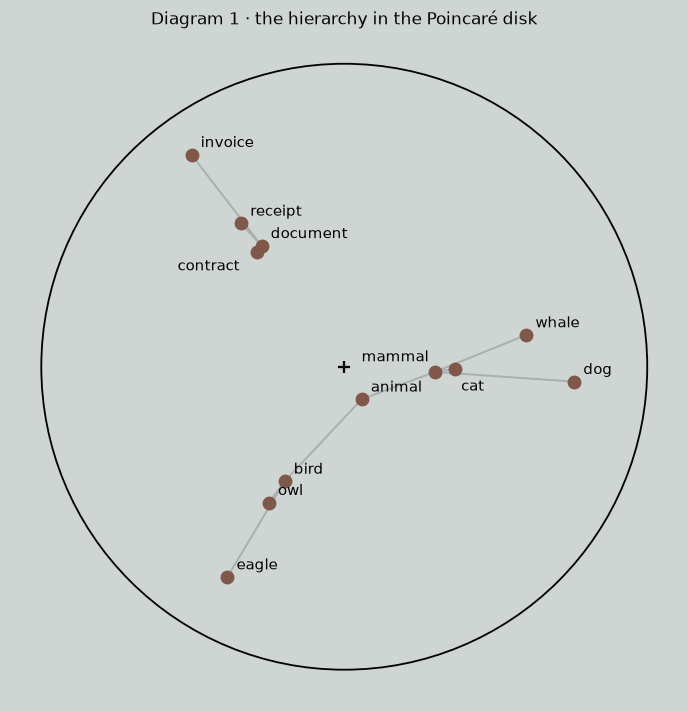

In [3]:
offsets = {"cat": (4, -14), "contract": (-52, -12), "mammal": (-48, 7)}
fig, ax = plt.subplots(figsize=(6.6, 6.6))
disk(ax, "Diagram 1 · the hierarchy in the Poincaré disk")
for child, parent in rels:
    ax.plot([emb[child].real, emb[parent].real], [emb[child].imag, emb[parent].imag], color=LIGHT_GREY, lw=1.3, zorder=1)
for w, z in emb.items():
    ax.scatter(z.real, z.imag, color=POINT, s=65, zorder=3)
    ax.annotate(w, (z.real, z.imag), xytext=offsets.get(w, (6, 5)), textcoords="offset points", fontsize=10)
ax.scatter(0, 0, marker="+", color=TEXT, s=70)
plt.tight_layout(); plt.show()

**What you're seeing:** general concepts sit nearer the centre (animal, and document with its branch) and specific ones nearer the edge (dog, owl, eagle, invoice). Each branch heads off in its own direction, mammals to the right, birds down and to the left, documents up and to the left. Distance from the centre is roughly depth in the hierarchy, and direction is roughly the branch. It's a 2-d toy with twelve words, so it isn't perfect (contract sits a touch closer to the centre than document), but the pattern is clear.

## Step 2 · The group and the moving frame

**The group.** The orientation-preserving isometries of the Poincaré disk are

$$z \;\longmapsto\; e^{i\theta}\,\frac{z - a}{1 - \bar{a} z}, \qquad |a| < 1,\ \theta \in \mathbb{R}.$$

It's a 3-dimensional group (two real numbers in $a$, one in $\theta$). It acts on **pairs** of points (a query and a candidate), which form a 4-dimensional space, so we expect $4 - 3 = 1$ invariant.

**The recipe** (Fels & Olver, Acta Appl. Math., 1998 and 1999): choose a normalisation, solve for the group element, read off what's left.

- **Normalisation 1.** Send the query $a$ to $0$. This fixes the Möbius part of the group element: $\rho(z) = (z - a)/(1 - \bar{a}z)$.
- **Normalisation 2.** Rotate so that the image of $b$ lies on the positive real axis. This fixes $\theta$.
- **What's left.** One number, $r = |\rho(b)|$. Rotating onto the axis doesn't change a modulus, so we can read $r$ off straight after normalisation 1.

The hyperbolic distance from the centre to a point at Euclidean radius $r$ is $2\operatorname{artanh}(r)$, so that's the invariant we report.

In [4]:
def frame(a):              # the isometry that sends a to the centre
    return lambda z: (z - a) / (1 - np.conj(a) * z)

def invariant(a, b):       # normalise, then read off what is left
    r = abs(frame(a)(b))   # rotating onto the axis leaves only |w|
    return 2 * np.arctanh(r)

a, b = emb["dog"], emb["owl"]
w = frame(a)(b)                          # after normalisation 1
w_axis = np.exp(-1j * np.angle(w)) * w   # after normalisation 2

print(f"rho(a)         = {frame(a)(a)}")
print(f"rho(b)         = {w:.6f}")
print(f"after rotating = {w_axis.real:.6f} {w_axis.imag:+.1e}i   (real part > 0: {w_axis.real > 0})")
print(f"r = |rho(b)|   = {abs(w):.6f}")

rho(a)         = 0j
rho(b)         = -0.886072-0.074514j
after rotating = 0.889200 -2.1e-17i   (real part > 0: True)
r = |rho(b)|   = 0.889200


**What you're seeing:** the frame sends dog to exactly 0. Owl lands at $-0.886 - 0.075i$, and after the rotation it sits at 0.889200 on the positive real axis, with an imaginary part of $10^{-17}$, which is floating-point zero. So all that's left of the pair (dog, owl) is one number, $r = 0.8892$.

**Diagram 2**, the three-step picture from the slide, with the real embeddings of $a$ = dog and $b$ = owl. The dashed curve is the geodesic (the hyperbolic straight line) between them.

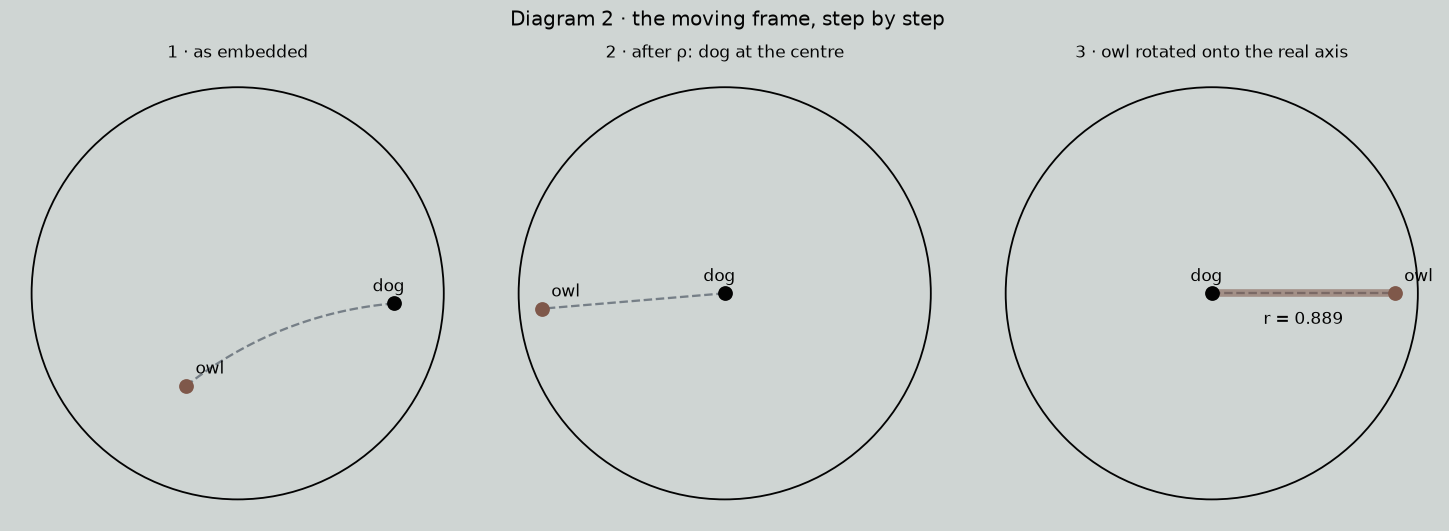

In [5]:
def geodesic(p, q, n=80):              # slide p to the centre, draw a straight segment, slide back
    back = lambda z: (z + p) / (1 + np.conj(p) * z)
    return back(np.linspace(0, 1, n) * frame(p)(q))

panels = [("1 · as embedded", a, b), ("2 · after ρ: dog at the centre", 0j, w), ("3 · owl rotated onto the real axis", 0j, w_axis)]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8))
for ax, (title, p, q) in zip(axes, panels):
    disk(ax, title)
    g = geodesic(p, q); ax.plot(g.real, g.imag, color=SLATE, lw=1.5, ls="--", zorder=1)
    ax.scatter(p.real, p.imag, color=QUERY, s=75, zorder=3); ax.annotate("dog", (p.real, p.imag), xytext=(-14, 8), textcoords="offset points")
    ax.scatter(q.real, q.imag, color=POINT, s=75, zorder=3); ax.annotate("owl", (q.real, q.imag), xytext=(6, 8), textcoords="offset points")
axes[2].plot([0, w_axis.real], [0, 0], color=POINT, lw=5, alpha=0.55, zorder=2)
axes[2].annotate(f"r = {abs(w):.3f}", (w_axis.real / 2, 0), xytext=(0, -20), textcoords="offset points", ha="center")
fig.suptitle("Diagram 2 · the moving frame, step by step", y=1.0)
plt.tight_layout(); plt.show()

**What you're seeing:** the three steps of the moving frame on real embeddings. In panel 1 the geodesic between dog and owl is a curved arc. In panel 2 the frame has slid dog to the centre, and the geodesic becomes a straight line, because geodesics through the centre are straight. In panel 3 the rotation lays owl on the positive real axis. The highlighted segment, $r = 0.889$, is the only information that survives, and $2\operatorname{artanh}(0.889) = 2.836$.

## Step 3 · The invariant is the hyperbolic distance

Now compare the invariant with the Poincaré distance formula and with gensim's own `model.kv.distance`.

In [6]:
a, b = emb["dog"], emb["owl"]
pf = np.arccosh(1 + 2 * abs(a - b) ** 2 / ((1 - abs(a) ** 2) * (1 - abs(b) ** 2)))
print(f"invariant(dog, owl)            = {invariant(a, b):.15f}")
print(f"Poincaré formula               = {pf:.15f}")
print(f"model.kv.distance('dog','owl') = {model.kv.distance('dog', 'owl'):.15f}")

invariant(dog, owl)            = 2.836180698966745
Poincaré formula               = 2.836180698966746
model.kv.distance('dog','owl') = 2.836180698966746


**What you're seeing:** three different routes to the same number, 2.83618069896674…, agreeing to the last couple of digits of double precision. That's the moving frame, the textbook Poincaré distance formula and gensim's own implementation, all matching the value on the slide.

Here's the bit I love. We never typed the distance formula into `invariant`. All we did was move the query to the centre and read off what the symmetry couldn't change, and the frame handed us the hyperbolic distance as the only thing that survives.

One pair could be a coincidence, so let's check every pair of words.

In [7]:
words = list(emb)
worst_formula = worst_gensim = 0.0
for u in words:
    for v in words:
        if u == v:
            continue
        zu, zv = emb[u], emb[v]
        formula = np.arccosh(1 + 2 * abs(zu - zv) ** 2 / ((1 - abs(zu) ** 2) * (1 - abs(zv) ** 2)))
        worst_formula = max(worst_formula, abs(invariant(zu, zv) - formula))
        worst_gensim = max(worst_gensim, abs(invariant(zu, zv) - model.kv.distance(u, v)))
print(f"{len(words) * (len(words) - 1)} ordered pairs")
print(f"largest |invariant - Poincaré formula|: {worst_formula:.1e}")
print(f"largest |invariant - gensim distance|:  {worst_gensim:.1e}")

132 ordered pairs
largest |invariant - Poincaré formula|: 1.1e-14
largest |invariant - gensim distance|:  1.1e-14


**What you're seeing:** over all 132 ordered pairs, the largest difference between the invariant and the Poincaré formula (and gensim's distance) is about $10^{-14}$. That's the size of rounding errors in double precision, so the invariant **is** the hyperbolic distance, for every pair.

## Step 4 · Search

Search is now just "sort by the invariant". For a query word, compute the invariant to every other word and return the $k$ smallest.

In [8]:
def search(q, k=3):
    others = [w for w in emb if w != q]
    return sorted(others, key=lambda w: invariant(emb[q], emb[w]))[:k]

print("search('dog') =", search("dog"))
print()
print(f"{'query':<10}{'1st':<20}{'2nd':<20}{'3rd':<20}")
for q in ["dog", "owl", "invoice", "animal"]:
    cells_ = [f"{w} ({invariant(emb[q], emb[w]):.4f})" for w in search(q)]
    print(f"{q:<10}" + "".join(f"{c:<20}" for c in cells_))

search('dog') = ['whale', 'cat', 'mammal']

query     1st                 2nd                 3rd                 
dog       whale (0.8328)      cat (1.2282)        mammal (1.3751)     
owl       bird (0.2245)       animal (1.0307)     eagle (1.0313)      
invoice   receipt (1.2729)    document (1.5524)   contract (1.5736)   
animal    mammal (0.5380)     cat (0.6871)        bird (0.8065)       


**What you're seeing:** `search("dog")` returns `['whale', 'cat', 'mammal']`, matching the slide. Look at the pattern in the table. For dog it's the two siblings first (whale and cat, the other mammals) and then the parent (mammal). For owl it's the parent bird, then animal and eagle almost tied (1.0307 and 1.0313). For invoice it's the sibling receipt, then the parent document, then the other sibling contract. The search retrieves by hierarchy because the geometry stores the hierarchy.

**Diagram 3.** The query "dog" with its top 3 neighbours, each joined to it by a geodesic and labelled with its distance.

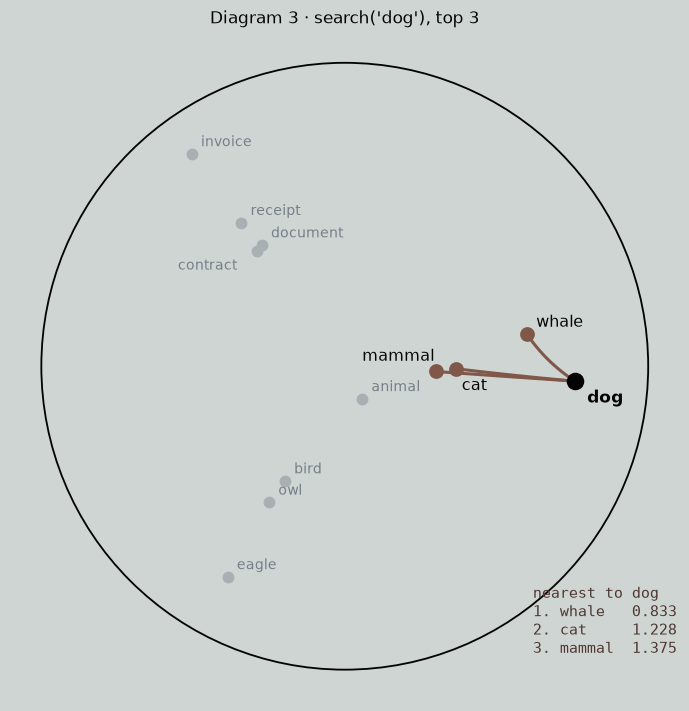

In [9]:
q = "dog"
fig, ax = plt.subplots(figsize=(6.6, 6.6))
disk(ax, "Diagram 3 · search('dog'), top 3")
top = search(q)
for w, z in emb.items():
    if w == q:
        continue
    faded = w not in top
    ax.scatter(z.real, z.imag, color=LIGHT_GREY if faded else POINT, s=45 if faded else 75, zorder=3)
    ax.annotate(w, (z.real, z.imag), xytext=offsets.get(w, (6, 5)), textcoords="offset points",
                fontsize=9 if faded else 10.5, color=SLATE if faded else TEXT)
for rank, w in enumerate(top, 1):
    g = geodesic(emb[q], emb[w]); ax.plot(g.real, g.imag, color=POINT, lw=2, zorder=2)
table = "\n".join(f"{rank}. {w:<7} {invariant(emb[q], emb[w]):.3f}" for rank, w in enumerate(top, 1))
ax.text(0.62, -0.72, "nearest to dog\n" + table, fontsize=10, family="monospace", va="top", color=DARK_BROWN)
ax.scatter(emb[q].real, emb[q].imag, color=QUERY, s=110, zorder=4)
ax.annotate(q, (emb[q].real, emb[q].imag), xytext=(8, -14), textcoords="offset points", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

**What you're seeing:** dog in black with its three nearest neighbours joined by geodesics, and their distances in the corner. Everything in the other branches (birds, documents) is faded out, and it's much further away, which is exactly what you want from a search over a taxonomy.

## Step 5 · Nothing arbitrary: move everything

The point of a frame is that the answer can't depend on where things happen to sit. So let's move the whole embedding with an isometry and check. First the single isometry from the slide.

In [10]:
g = lambda z: np.exp(0.7j) * (z - 0.2j) / (1 + 0.2j * z)   # any isometry
a, b = emb["dog"], emb["owl"]
print(np.isclose(invariant(g(a), g(b)), invariant(a, b)))

True


**What you're seeing:** `True`, as on the slide. Moving both points by the isometry $g$ doesn't change the invariant at all.

Now 100 random isometries (random angle $\theta$, random $a$ with $|a| < 0.9$, seed 0). For each one we move all twelve words, rerun `search` for every word, and compare with the original rankings. We check the top 3 and the full ranking of all 11 other words.

In [11]:
def search_in(E, q, k=3):
    others = [w for w in E if w != q]
    return sorted(others, key=lambda w: invariant(E[q], E[w]))[:k]

def random_isometry(rng):
    c = 0.9 * np.sqrt(rng.uniform()) * np.exp(2j * np.pi * rng.uniform())   # |c| < 0.9
    theta = rng.uniform(0, 2 * np.pi)
    return (lambda z: np.exp(1j * theta) * (z - c) / (1 - np.conj(c) * z)), c, theta

rng = np.random.default_rng(SEED)
original_top3 = {q: search_in(emb, q) for q in emb}
original_full = {q: search_in(emb, q, k=11) for q in emb}
isometries = [random_isometry(rng) for _ in range(100)]

same_top3 = same_full = 0
for h, _, _ in isometries:
    moved = {w: h(z) for w, z in emb.items()}
    same_top3 += all(search_in(moved, q) == original_top3[q] for q in emb)
    same_full += all(search_in(moved, q, k=11) == original_full[q] for q in emb)

print(f"{same_top3} / 100 isometries: identical top-3 rankings for all {len(emb)} queries")
print(f"{same_full} / 100 isometries: identical full rankings for all {len(emb)} queries")

100 / 100 isometries: identical top-3 rankings for all 12 queries
100 / 100 isometries: identical full rankings for all 12 queries


**What you're seeing:** for all 100 random isometries, every one of the 12 queries gets exactly the same answer, and so does the full ranking of all 11 other words. Wherever you put the embedding, the moving frame finds the same standard position, so the search can't depend on that choice.

**Diagram 4.** The original embedding next to the same embedding after one of those random isometries. Isometries that shift the disk a long way squash everything against the edge, which is correct but hard to read, so for the picture we take the first of the 100 with a moderate shift ($0.3 < |a| < 0.6$). The picture changes completely, and the search results underneath don't.

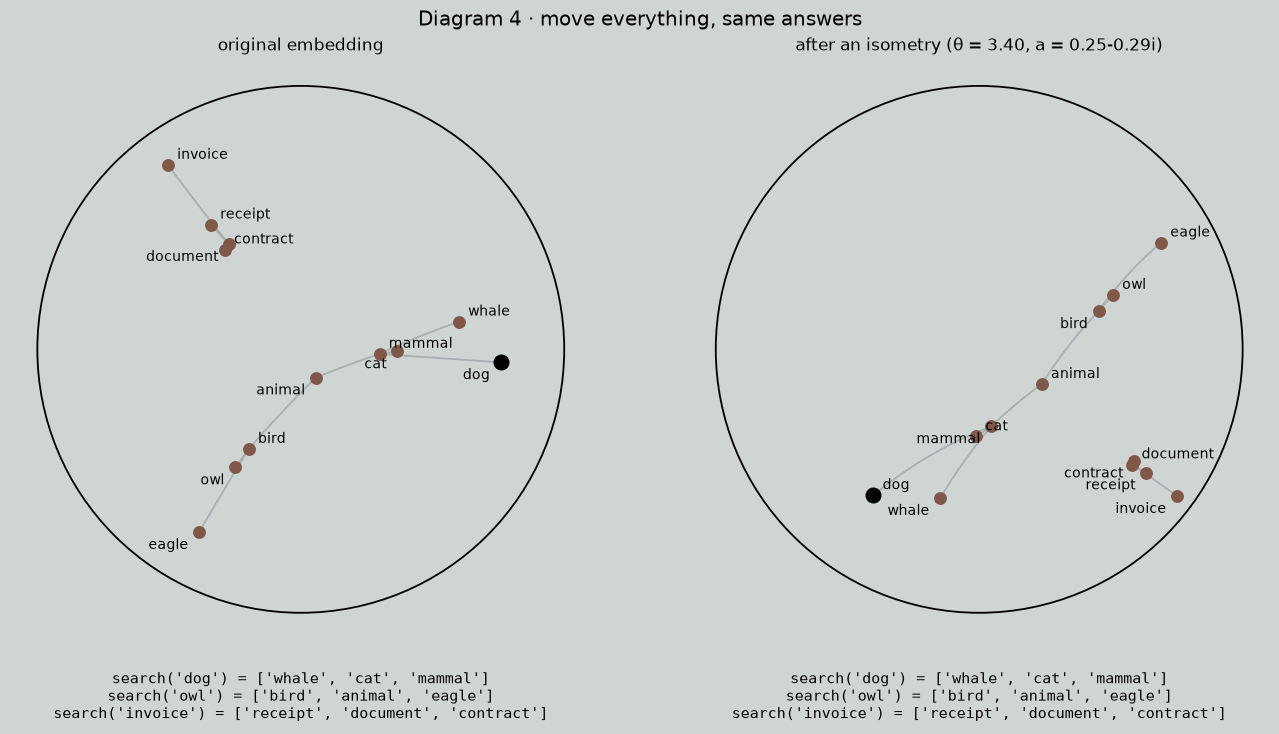

In [12]:
h, c, theta = next(iso for iso in isometries if 0.3 < abs(iso[1]) < 0.6)
moved = {w: h(z) for w, z in emb.items()}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.4))
for ax, E, title in [(axes[0], emb, "original embedding"),
                     (axes[1], moved, f"after an isometry (θ = {theta:.2f}, a = {c.real:.2f}{c.imag:+.2f}i)")]:
    disk(ax, title)
    for child, parent in rels:
        gg = geodesic(E[child], E[parent]); ax.plot(gg.real, gg.imag, color=LIGHT_GREY, lw=1.2, zorder=1)
    for w, z in E.items():
        ax.scatter(z.real, z.imag, color=QUERY if w == "dog" else POINT, s=90 if w == "dog" else 55, zorder=3)
    for k, w in enumerate(sorted(E, key=lambda w: (round(E[w].real, 1), E[w].imag))):   # alternate sides so neighbours don't collide
        z = E[w]
        ax.annotate(w, (z.real, z.imag), xytext=(6, 4) if k % 2 == 0 else (-7, -11), ha="left" if k % 2 == 0 else "right",
                    textcoords="offset points", fontsize=9)
    lines = [f"search('{q_}') = {search_in(E, q_)}" for q_ in ["dog", "owl", "invoice"]]
    ax.text(0, -1.22, "\n".join(lines), ha="center", va="top", fontsize=9.5, family="monospace")
fig.suptitle("Diagram 4 · move everything, same answers", y=0.99)
plt.tight_layout(); plt.show()

**What you're seeing:** on the right, the same twelve words after an isometry. The branches point in new directions, dog has swung round to the bottom left, and the documents now sit at the bottom right. If you only looked at the picture, you'd think it was a different embedding. The three searches printed underneath are identical on both sides.

**The contrast with cosine.** Do the same thing with cosine similarity between the raw 2-d vectors, which is what you'd get if you dropped these points into an ordinary vector database.

In [13]:
def cosine(u, v):
    return (u.real * v.real + u.imag * v.imag) / (abs(u) * abs(v))

def cosine_search(E, q, k=3):
    others = [w for w in E if w != q]
    return sorted(others, key=lambda w: -cosine(E[q], E[w]))[:k]

print("cosine with 'dog', before and after the isometry in Diagram 4:")
for w in ["whale", "cat", "mammal", "owl"]:
    print(f"  {w:<7} {cosine(emb['dog'], emb[w]):7.3f}  ->  {cosine(moved['dog'], moved[w]):7.3f}")
print("\ncosine_search('dog') before:", cosine_search(emb, "dog"))
print("cosine_search('dog') after: ", cosine_search(moved, "dog"))

changed = 0
for h_, _, _ in isometries:
    m = {w: h_(z) for w, z in emb.items()}
    changed += any(cosine_search(m, q) != cosine_search(emb, q) for q in emb)
print(f"\ncosine top-3 changed for at least one query under {changed} / 100 isometries")

cosine with 'dog', before and after the isometry in Diagram 4:
  whale     0.972  ->    0.932
  cat       0.999  ->    0.829
  mammal    1.000  ->    0.710
  owl      -0.428  ->   -0.848

cosine_search('dog') before: ['mammal', 'cat', 'whale']
cosine_search('dog') after:  ['whale', 'cat', 'mammal']

cosine top-3 changed for at least one query under 100 / 100 isometries


**What you're seeing:** cosine on the raw 2-d vectors moves around a lot. Dog's cosine with mammal drops from 1.000 to 0.710 and with cat from 0.999 to 0.829, and the cosine ranking for dog changes from `['mammal', 'cat', 'whale']` to `['whale', 'cat', 'mammal']`. Across all 100 isometries, cosine changes at least one query's top 3 every single time. This is the arbitrary-cosine problem from the talk, measured. Cosine depends on where the embedding happens to sit, and the frame removes that dependence.

## Step 6 · Takeaway

Choose the symmetry, use a moving frame to put everything in standard position, then measure only what survives. Here the thing that survived turned out to be the hyperbolic distance, and the search results didn't change under any of the 100 isometries we threw at them. Cosine changed every time.

If you want to see where this goes beyond smooth spaces, the discrete version (difference moving frames, and Noether's conservation laws for finite difference schemes) is in two of my papers: Mansfield, Rojo-Echeburúa, Hydon & Peng, *Moving Frames and Noether's Finite Difference Conservation Laws I* (Trans. Math. Appl., 2019), and Mansfield & Rojo-Echeburúa, *Moving Frames and Noether's Finite Difference Conservation Laws II* (Trans. Math. Appl., 2019).